In [1]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

## Image Stitching with Homographies

This project implements a grayscale panorama stitching pipeline in Python. Homography transformations align overlapping images, while custom bilinear interpolation samples pixel intensities during image warping. Exposure matching and alpha blending reduce visible seams between the images.

The pipeline covers:

- **Point visualisation:** Display reference points to inspect image correspondences.
- **Homography transformation:** Map points between image coordinate systems.
- **Bilinear interpolation:** Estimate pixel intensities at fractional coordinates.
- **Image stitching:** Warp and combine overlapping images onto a shared canvas.
- **Seam blending:** Match brightness, feather overlapping regions and crop image borders.
- **Feature-based alignment:** Use SIFT feature matching and RANSAC homography estimation to stitch personally captured photographs.

### Implementation

Image warping, interpolation and blending are implemented using NumPy. OpenCV handles image loading, feature extraction, feature matching and homography estimation. Matplotlib visualises intermediate steps and final panoramas.

## Step 1: Reference Point Visualisation

Five reference points are defined in homogeneous coordinates and plotted as red crosses on the left image:

(446, 499, 1), (383, 590, 1), (296, 499, 1), (282, 511, 1), (401, 508, 1).

Each point \((x, y, w)\) is converted to 2D pixel coordinates as \((x/w, y/w)\). These points provide a visual reference for checking alignment after applying the homography transformation.

In [2]:
# Load the left image in grayscale
img_left = cv2.imread('left.jpg', 0)

# Define the points in homogeneous coordinates
points_homog = np.array([
    [446, 499, 1],
    [383, 590, 1],
    [296, 499, 1],
    [282, 511, 1],
    [401, 508, 1]
])

# Convert to 2D image pixel coordinates (x, y) by dividing x and y by the w (third) component 
points_2d = points_homog[:, :2] / points_homog[:, 2:3]

TypeError: Image data of dtype object cannot be converted to float

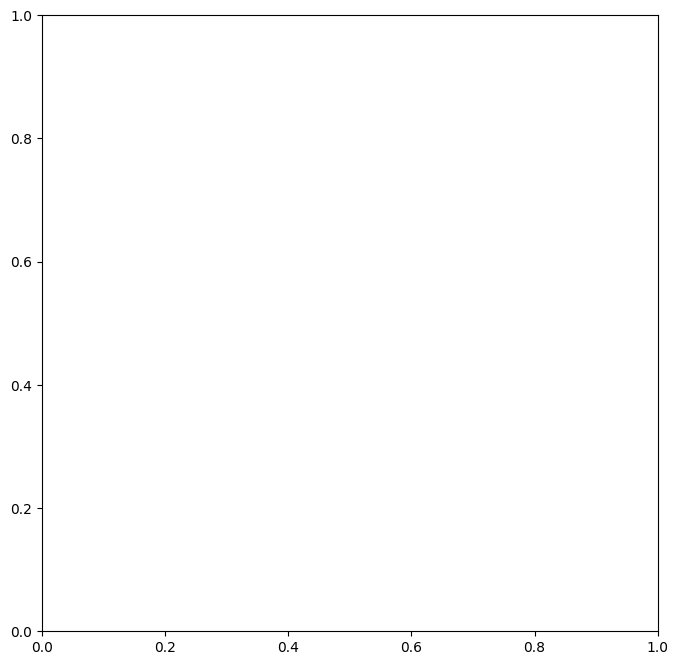

In [3]:
# Show the result here
plt.figure(figsize=(10, 8))
plt.imshow(img_left, cmap='gray')

# Plotting the red crosses
plt.scatter(points_2d[:, 0], points_2d[:, 1], c='red', marker='x', s=100, label='Test Points')

plt.title("Task 1: Test Points on Left Image")
plt.legend()
plt.show()

# Step 2: Homography Transformation


A homography maps the reference points from the left image to their corresponding locations in the right image:

$$
\mathbf{x}_R = H\mathbf{x}_L,
\qquad
H =
\begin{bmatrix}
1.6011 & 0.0277 & -393.5701 \
0.3242 & 1.5119 & -228.8918 \
0.0009 & 0.0002 & 1.0000
\end{bmatrix}
$$

The transformed homogeneous coordinates are normalised by dividing their first two components by the third. The resulting 2D points are plotted as red crosses on the right image to visually assess the mapping.


In [ ]:
# Load the right image
img_right = cv2.imread('right.jpg', 0)

# Define the Homography matrix H as provided 
H = np.array([
    [1.6011, 0.0277, -393.5701],
    [0.3242, 1.5119, -228.8918],
    [0.0009, 0.0002, 1.0000]
])

# Apply the transformation formula: x_R = H * x_L
points_R_homog = (H @ points_homog.T).T

# Normalize to get 2D pixel coordinates
points_R_2d = points_R_homog[:, :2] / points_R_homog[:, 2:3]


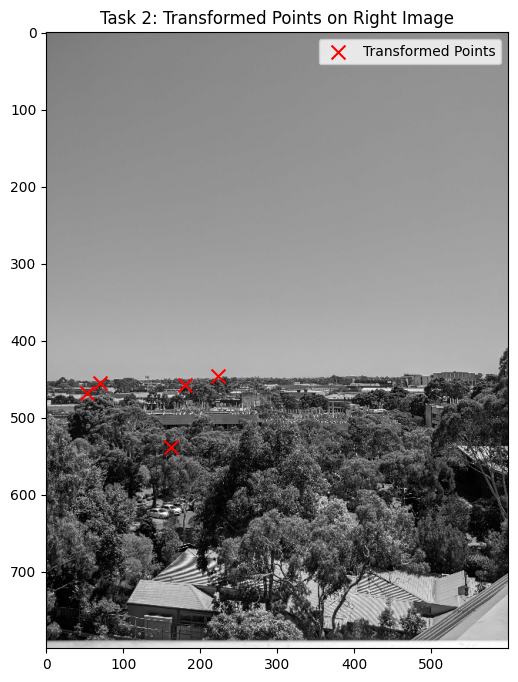

Transformed coordinates in right image:
Point 1: x=222.72, y=446.40
Point 2: x=161.34, y=538.25
Point 3: x=68.93, y=454.92
Point 4: x=53.17, y=468.37
Point 5: x=179.52, y=457.54


In [ ]:
# Print results here
plt.figure(figsize=(10, 8))
plt.imshow(img_right, cmap='gray')
plt.scatter(points_R_2d[:, 0], points_R_2d[:, 1], c='red', marker='x', s=100, label='Transformed Points')

plt.title("Task 2: Transformed Points on Right Image")
plt.legend()
plt.show()

# Print results to check
print("Transformed coordinates in right image:")
for i, pt in enumerate(points_R_2d):
    print(f"Point {i+1}: x={pt[0]:.2f}, y={pt[1]:.2f}")

# Step 3: Bilinear Interpolation

Homography transformations can map points to fractional pixel coordinates. A custom bilinear interpolation function estimates the intensity at each mapped location in right.jpg using a weighted average of its four neighbouring pixels. The weights depend on the point’s horizontal and vertical distances from those neighbours.

Interpolated intensities are printed for each transformed reference point. The expected values for the first and last points are approximately 176 and 73, respectively, providing a numerical check of the implementation.

In [ ]:
def bilinear_interpolate(img, x, y):
    # Get image dimensions
    height, width = img.shape
    
    # Determine the coordinates of the four surrounding pixels
    x0 = np.floor(x).astype(int)
    x1 = x0 + 1
    y0 = np.floor(y).astype(int)
    y1 = y0 + 1
    
    # Check if the surrounding pixels are within image bounds
    mask = (x0 >= 0) & (x1 < width) & (y0 >= 0) & (y1 < height)

    # Initialize output array with zeros
    output = np.zeros_like(x, dtype=float)

    # Extract intensities for valid pixels 
    Ia = img[y0[mask], x0[mask]]
    Ib = img[y1[mask], x0[mask]]
    Ic = img[y0[mask], x1[mask]]
    Id = img[y1[mask], x1[mask]]

    # Calculate weights for valid pixels
    dx = x[mask] - x0[mask]
    dy = y[mask] - y0[mask]
    
    # Compute the bilinear interpolation for valid pixels
    wa = (1 - dx) * (1 - dy)
    wb = (1 - dx) * dy
    wc = dx * (1 - dy)
    wd = dx * dy

    # Compute weighted average and place back into the output array
    output[mask] = wa * Ia + wb * Ib + wc * Ic + wd * Id
    
    return output

In [ ]:
# Show results here
# Use the transformed points from Task 2
x_R = points_R_2d[:, 0]
y_R = points_R_2d[:, 1]

# Call the function to get the interpolated intensities at the transformed points
intensities = bilinear_interpolate(img_right, x_R, y_R)

print("Task 3: Interpolated Intensities")
for i, val in enumerate(intensities):
    print(f"Point {i+1}: Intensity = {val:.2f}")

Task 3: Interpolated Intensities
Point 1: Intensity = 176.00
Point 2: Intensity = 38.47
Point 3: Intensity = 69.83
Point 4: Intensity = 58.19
Point 5: Intensity = 74.51


# Step 4: Image Warping and Stitching

The images are combined on a 1200 × 800 pixel canvas using the left image’s coordinate system. The left image is placed at the canvas origin, and canvas coordinates are mapped into the right image using the homography.

Valid mapped coordinates are sampled using custom bilinear interpolation; locations outside the right image receive a value of zero. The resulting panorama demonstrates geometric alignment, with a visible seam between the images before exposure correction and blending.

In [ ]:
def stitching_img(img_L, img_R, H):
    
    # Create a 1200x800(width x height) canvas to hold the stitched image
    canvas_h, canvas_w = 800, 1200

    # Initialize the stitched image with zeros 
    stitched_img = np.zeros((canvas_h, canvas_w), dtype=np.uint8)
    
    # Place the left image onto the canvas
    h_L, w_L = img_L.shape
    stitched_img[:h_L, :w_L] = img_L  
    
    # Map every canvas pixel through H to find where it comes from in img_R
    y_range = np.arange(canvas_h)
    x_range = np.arange(canvas_w)          
    x_grid, y_grid = np.meshgrid(x_range, y_range)
    
    # Flatten grids for transformation
    x_flat = x_grid.ravel()
    y_flat = y_grid.ravel()
    
    # Map pixels back to the right image using Homography
    points_L_homog = np.vstack([x_flat, y_flat, np.ones_like(x_flat)])
    points_R_homog = H @ points_L_homog

    # Normalize to get 2D pixel coordinates
    x_R_mapped = points_R_homog[0, :] / points_R_homog[2, :]
    y_R_mapped = points_R_homog[1, :] / points_R_homog[2, :]

    # Get intensities for the entire right image 
    right_side_intensities = bilinear_interpolate(img_right, x_R_mapped, y_R_mapped)
    
    # Reshape the intensities back to the canvas size
    warped_R = right_side_intensities.reshape(canvas_h, canvas_w).astype(np.uint8)
    
    # Create a mask of where the right image actually exists
    mask_R = warped_R > 0
    
    # Apply right image over the canvas
    stitched_img[mask_R] = warped_R[mask_R]
    
    return stitched_img

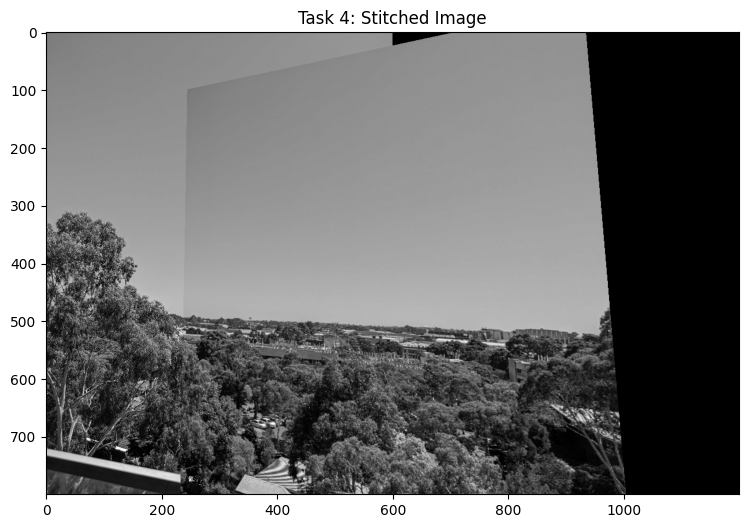

In [ ]:
# Show results here
stitched_image = stitching_img(img_left, img_right, H)

plt.figure(figsize=(12, 6))
plt.imshow(stitched_image, cmap='gray')
plt.title("Task 4: Stitched Image")
plt.show()

# Step 5: Exposure Matching and Seam Blending

The stitched panorama is refined through brightness correction, alpha blending and automatic cropping.

Brightness correction: The right image’s intensity is scaled using the ratio of mean intensities in the overlapping region to reduce exposure differences.

Alpha blending: A linear weight transition across the overlap gradually combines the images, softening the visible seam.

Automatic cropping: Intensity-based checks trim dark borders introduced by image warping.

These refinements produce a smoother transition between the images and reduce empty space around the panorama.

In [ ]:
def blending_img(img_L, img_R, H):
    
    # Create a canvas to hold the blended image
    h_L, w_L = img_L.shape
    h_R, w_R = img_R.shape
    canvas_h, canvas_w = h_L, w_L + w_R  
    y_coords, x_coords = np.mgrid[0:canvas_h, 0:canvas_w]
    
    # Map coordinates back to the right image using Homography
    coords_L = np.vstack([x_coords.ravel(), y_coords.ravel(), np.ones(x_coords.ravel().size)])
    coords_R_homog = H @ coords_L
    x_R_all = (coords_R_homog[0] / coords_R_homog[2]).reshape(canvas_h, canvas_w)
    y_R_all = (coords_R_homog[1] / coords_R_homog[2]).reshape(canvas_h, canvas_w)

    # Create masks for valid pixels in left and right images
    mask_L = (x_coords < w_L) & (y_coords < h_L)
    mask_R = (x_R_all >= 0) & (x_R_all < w_R - 1) & (y_R_all >= 0) & (y_R_all < h_R - 1)
    overlap = mask_L & mask_R
    
    # Brightness scaling 
    brightness_scale = 1.0
    if np.any(overlap):
        
        # Create a padded version of the left image to sample intensities in the overlap area
        img_L_padded_temp = np.zeros((canvas_h, canvas_w), dtype=np.float32)
        img_L_padded_temp[:h_L, :w_L] = img_L

        # Sample intensities from Left and Right in the overlap area
        vals_L = img_L_padded_temp[overlap]
        
        # Use function to get Right intensities for the overlap
        vals_R = bilinear_interpolate(img_R, x_R_all[overlap], y_R_all[overlap])
        
        # Compute mean intensities and determine scaling factor
        mean_L = np.mean(vals_L)
        mean_R = np.mean(vals_R)
        
        # Avoid division by zero 
        if mean_R > 0:
            brightness_scale = np.clip(mean_L / mean_R, 0.5, 2.0)

    # Generate warped right image using the same interpolation for the entire canvas
    warped_R = bilinear_interpolate(img_R, x_R_all, y_R_all) * brightness_scale
    
    # Createa vectorized alpha blend mask
    # Initialize: 0.0 where only Left exists, 1.0 where only right exists
    alpha = np.zeros((canvas_h, canvas_w), dtype=np.float32)
    alpha[mask_R] = 1.0 
    
    # Smooth the transition in the overlap zone
    # For each row in the overlap, create a gradient from 0 to 1
    for y in range(canvas_h):
        if np.any(overlap[y]):
            x_indices = np.where(overlap[y])[0]
            x_start, x_end = x_indices[0], x_indices[-1]
            # Create a linear ramp for the width of the overlap in this row
            num_steps = x_end - x_start + 1
            alpha[y, x_start:x_end+1] = np.linspace(0, 1, num_steps)

    # Prepare Left image on the large canvas
    img_L_padded = np.zeros((canvas_h, canvas_w), dtype=np.float32)
    img_L_padded[:h_L, :w_L] = img_L
    
    # Linear interpolation: Result = (1 - alpha)*Left + alpha*Right
    output = (1 - alpha) * img_L_padded + alpha * warped_R
    output_uint8 = np.clip(output, 0, 255).astype(np.uint8)

    # Find rightmost col where top 10 rows all have data (not 0) 
    top_region = output_uint8[:10, :]  # check top 10 rows
    clean_cols = np.where(np.all(top_region > 10, axis=0))[0]
    non_zero_rows = np.where(np.any(output_uint8 > 10, axis=1))[0]
    if len(clean_cols) > 0 and len(non_zero_rows) > 0:
        output_uint8 = output_uint8[non_zero_rows[0]:non_zero_rows[-1]+1,
                                    :clean_cols[-1]+1]

    # Check for any rows that have content (not 0) and crop to those rows
    has_content = np.any(output_uint8 > 10, axis=1)
    if np.any(has_content):
        rows = np.where(has_content)[0]
        # Slice only the vertical (y) axis, leave width (x) untouched
        output_uint8 = output_uint8[rows[0]:rows[-1]+1, :]

    # Check for solid rows in the right portion of the image and crop to those rows
    check_area = output_uint8[:, w_L:]
    is_row_solid = np.all(check_area > 10, axis=1)

    if np.any(is_row_solid):
        # Get the range of solid rows
        solid_rows = np.where(is_row_solid)[0]
        y_start, y_end = solid_rows[0], solid_rows[-1]
        # Crop the height to these solid rows
        output_uint8 = output_uint8[y_start:y_end+1, :]

    return output_uint8

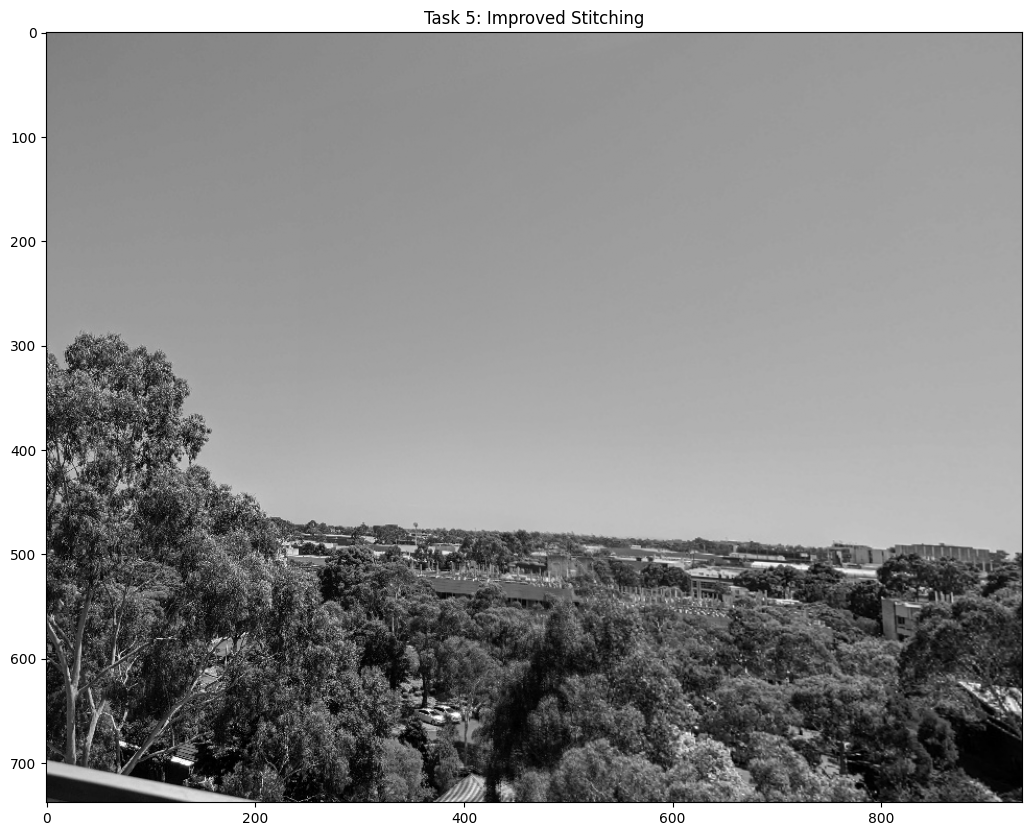

In [ ]:
# Show results here
better_stitched = blending_img(img_left, img_right, H)
 
plt.figure(figsize=(15, 10))
plt.imshow(better_stitched, cmap='gray')
plt.title("Task 5: Improved Stitching")
plt.show()

# Step 6: Feature-Based Panorama Generation

The stitching pipeline is applied to two personally captured photographs of the same scene with overlapping views.

SIFT detects keypoints and computes descriptors in both images. Features are matched using a brute-force matcher, with Lowe’s ratio test filtering ambiguous matches. RANSAC then estimates the homography while rejecting outlier correspondences.

The estimated homography aligns the images, which are combined using the custom bilinear interpolation, brightness correction, alpha blending and cropping functions to produce the final panorama.

In [ ]:
# Load my own images in grayscale
img_L = cv2.imread('my_left_photo.jpeg', 0)
img_R = cv2.imread('my_right_photo.jpeg', 0)

# Find key points (using cv2 SIFT (which allowed for matching keypoints))
# SIFT includes keypoint detection and descriptor computation in one step, so we can do both at once
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img_L, None)
kp2, des2 = sift.detectAndCompute(img_R, None)

# Match features (using cv2 BFMatcher with Lowe's Ratio Test to filter matches)
# BFMatcher with k=2 for Lowe's Ratio Test
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Lowe's Ratio Test to filter weak matches
# Check if the distance of the best match is less than 0.7 times the distance of the second-best match
good = []
for m, n in matches:
    if m.distance < 0.7 * n.distance:
        good.append(m)

# Check if the number of good matches is sufficient to compute a homography
if len(good) > 10:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

# Compute homography using RANSAC to filter out outliers
H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

# Use task 5 blending functi
final_result = blending_img(img_L, img_R, H)

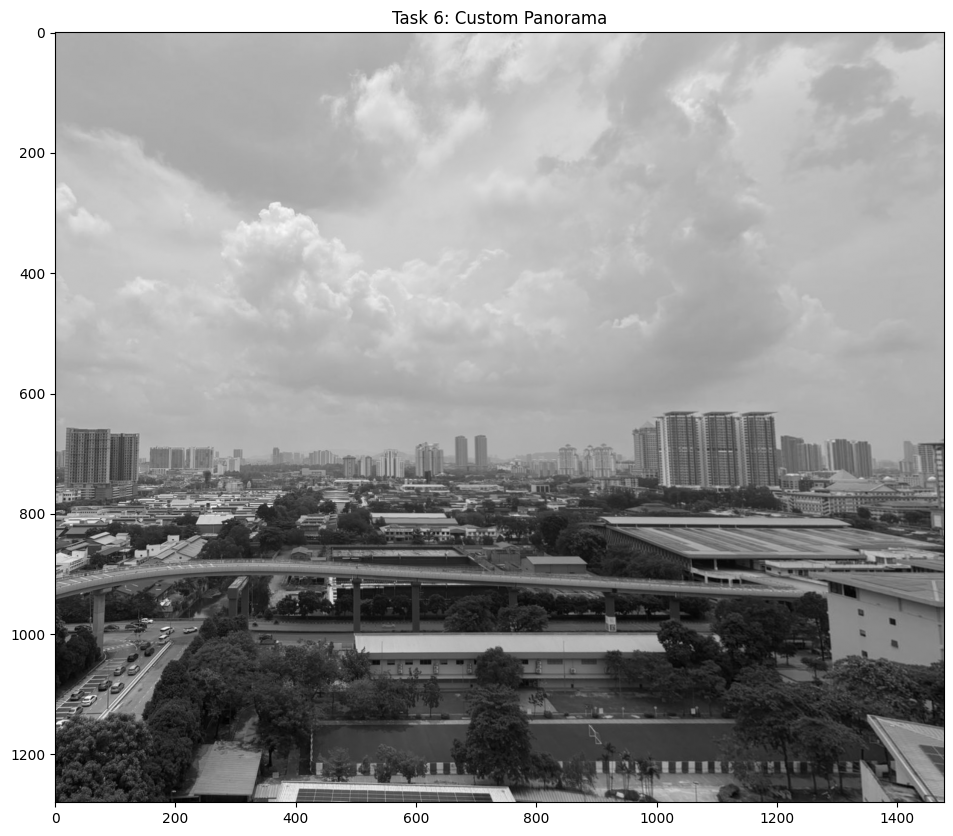

In [ ]:
# Show results here

plt.figure(figsize=(15, 10))
plt.imshow(final_result, cmap='gray')
plt.title("Task 6: Custom Panorama")
plt.show()



# Discussion:





# 1. Camera mechanics
Cameras map 3D coordinates to a 2D plane via the intrinsic matrix $K$. Because each photo is a unique perspective projection, creating a panorama requires a mathematical way to map the second camera's coordinate system back onto the first to ensure the scene remains coherent.

# 2. Homography
A homography ($3 \times 3$ matrix) relates points between images of a planar scene or a rotating camera. This was the essential "bridge" for Task 2; without it, I couldn't precisely determine where a pixel from the right image should sit in the left image's space.

# 3. Stitching and blending (Task3-5)
My initial implementation used nested `for-loops` to iterate through every pixel individually. While this was a logical starting point to understand the pixel-wise math, the execution time was incredibly slow. To achieve real-time performance, I refactored the code using vectorized masks with NumPy.

I chose this approach to combine several blending techniques simultaneously:
* **Brightness scaling:** I matched mean intensities in the overlap to prevent distracting exposure jumps at the seam.
* **Alpha blending:** Using `np.linspace` to feather the transition via $I_{out} = (1-\alpha)I_L + \alpha I_R$, applying the calculation instantly across the matrix.
* **Seam optimization:** I shifted the seam within the overlap to find the most seamless alignment point.

# 4. Geometric artifacts and cropping (Task5)
Warping created black wedges at the image edges. I wrote a cropping sequence to detect the boundaries of actual image data, trimming these borders to produce a professional, rectangular output.

# 5. Automated stitching and feature matching using cv2 (cv2 are allowed to used for extracting and matching keypoints, and computing homographies) (Task6) 
In Task 6, I switched to an automated pipeline. Unlike Tasks 1 and 2, I did not have fixed, pre-defined coordinates for my own photos, making manual point selection inefficient. I utilized:
* **SIFT:** To detect descriptors that remain stable despite rotation or zoom.
* **BFMatcher & Lowe’s Ratio Test:** To pair features while discarding ambiguous matches.
* **RANSAC:** Used within `cv2.findHomography` to ignore "outliers"—bad matches that would otherwise ruin the alignment.

> **Conclusion:** This project provided a vital hands-on look at how linear algebra and optimization solve real-world computer vision problems.